In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('netflix_titles.csv')
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,TV Show,3%,NaN,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil,"August 14, 2020",2020,TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...
1,s2,Movie,7:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, ...",Mexico,"December 23, 2016",2016,TV-MA,93 min,"Dramas, International Movies",After a devastating earthquake hits Mexico Cit...
2,s3,Movie,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence ...",Singapore,"December 20, 2018",2011,R,78 min,"Horror Movies, International Movies","When an army recruit is found dead, his fellow..."
3,s4,Movie,9,Shane Acker,"Elijah Wood, John C. Reilly, Jennifer Connelly...",United States,"November 16, 2017",2009,PG-13,80 min,"Action & Adventure, Independent Movies, Sci-Fi...","In a postapocalyptic world, rag-doll robots hi..."
4,s5,Movie,21,Robert Luketic,"Jim Sturgess, Kevin Spacey, Kate Bosworth, Aar...",United States,"January 1, 2020",2008,PG-13,123 min,Dramas,A brilliant group of students become card-coun...


In [2]:
df.shape

(7787, 12)

In [3]:
df['country'].str.split(',').str[0].str.strip().value_counts().head()

,count
country,
United States,2883
India,956
United Kingdom,577
Canada,259
Japan,237


In [5]:
df.isna().sum()

,0
show_id,0
type,0
title,0
director,2389
cast,718
country,507
date_added,10
release_year,0
rating,7
duration,0


In [6]:
# 1. fill missing countries, then keep only the FIRST country listed
df['country'] = df['country'].fillna('Unknown')
df['main_country'] = df['country'].str.split(',').str[0].str.strip()

# 2. the year a title was added to Netflix
df['year_added'] = pd.to_datetime(df['date_added'].str.strip(), format='%B %d, %Y', errors='coerce').dt.year.astype('Int64')

# 3. a simple group label: India or the rest of the world
df['origin'] = np.where(df['main_country'] == 'India', 'India', 'Rest of world')

# 4. a table with only movies, with the length as a number (in minutes)
movies = df[df['type'] == 'Movie'].copy()
movies['minutes'] = movies['duration'].str.replace(' min', '').astype(int)

df[['title', 'main_country', 'origin', 'year_added']].head()

,title,main_country,origin,year_added
0,3%,Brazil,Rest of world,2020
1,7:19,Mexico,Rest of world,2016
2,23:59,Singapore,Rest of world,2018
3,9,United States,Rest of world,2017
4,21,United States,Rest of world,2020


In [7]:
counts = df['type'].value_counts()
counts

,count
type,
Movie,5377
TV Show,2410


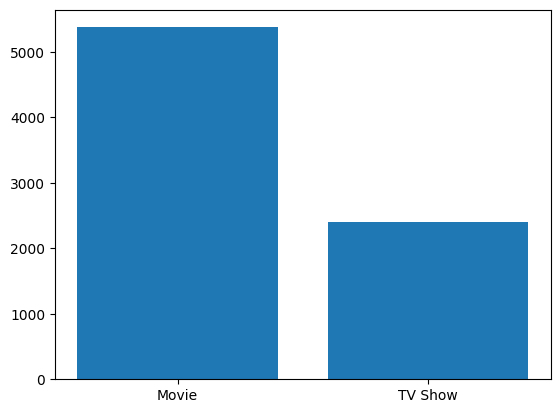

In [8]:
plt.bar(counts.index, counts.values)
plt.show()

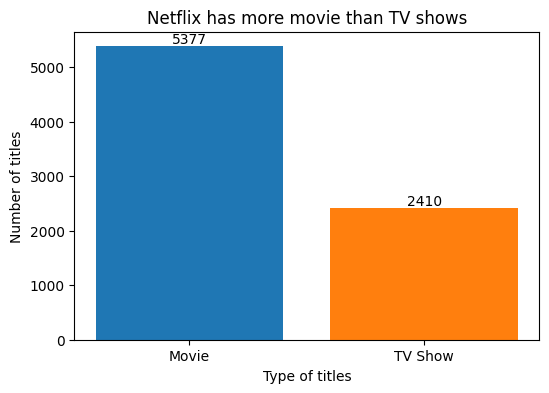

In [11]:
plt.figure(figsize=(6,4))
bars = plt.bar(counts.index, counts.values, color=['tab:blue', 'tab:orange'])
plt.bar_label(bars)
plt.title('Netflix has more movie than TV shows')
plt.xlabel('Type of titles')
plt.ylabel('Number of titles')
plt.show()

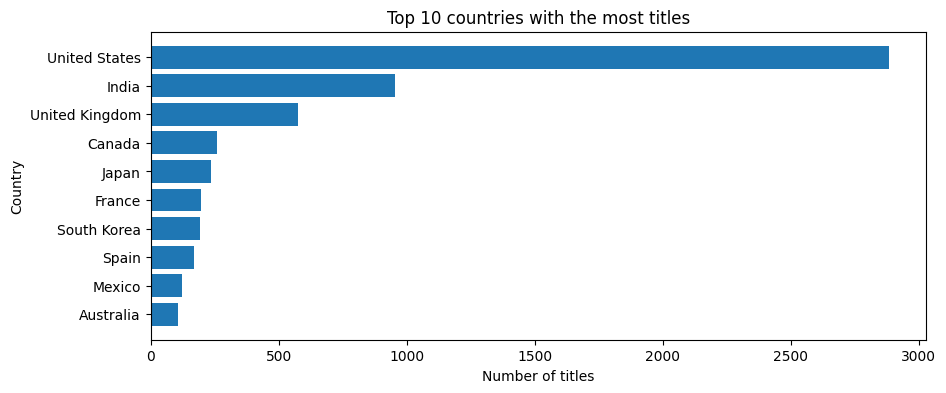

In [13]:
known = df[df['main_country'] != 'Unknown']
top10 = known['main_country'].value_counts().head(10).sort_values()

plt.figure(figsize=(10,4))
plt.barh(top10.index, top10.values)
plt.title('Top 10 countries with the most titles')
plt.xlabel('Number of titles')
plt.ylabel('Country')
plt.show()

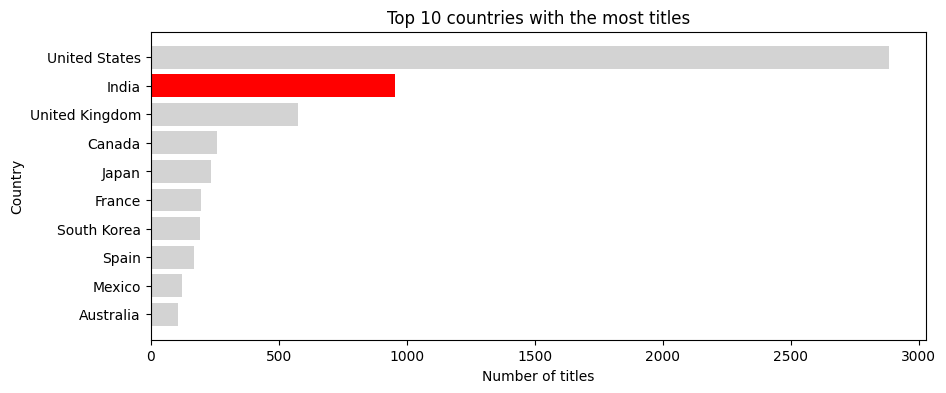

In [14]:
colors = ['red' if c == 'India' else 'lightgrey' for c in top10.index]


plt.figure(figsize=(10,4))
plt.barh(top10.index, top10.values, color = colors)
plt.title('Top 10 countries with the most titles')
plt.xlabel('Number of titles')
plt.ylabel('Country')
plt.show()

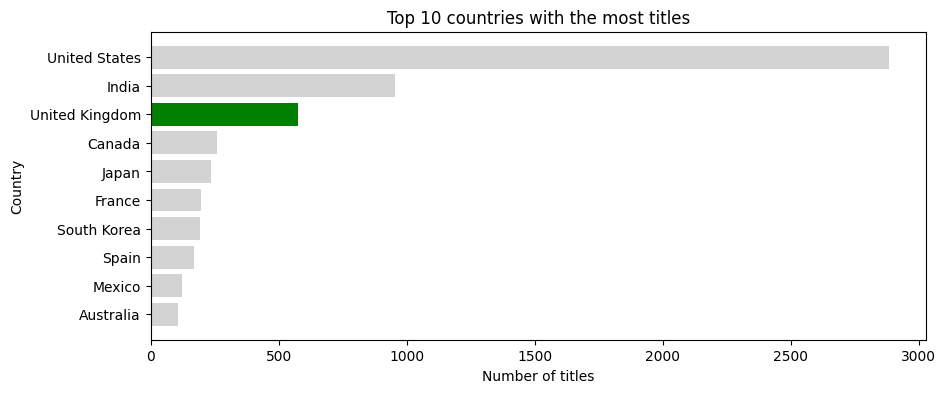

In [16]:
colors = ['green' if c == 'United Kingdom' else 'lightgrey' for c in top10.index]


plt.figure(figsize=(10,4))
plt.barh(top10.index, top10.values, color = colors)
plt.title('Top 10 countries with the most titles')
plt.xlabel('Number of titles')
plt.ylabel('Country')
plt.show()

#Histograms

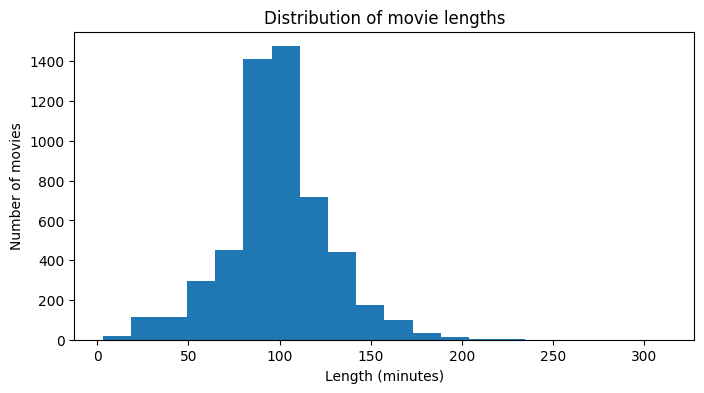

In [18]:
plt.figure(figsize=(8,4))
plt.hist(movies['minutes'], bins = 20)
plt.title('Distribution of movie lengths')
plt.xlabel('Length (minutes)')
plt.ylabel('Number of movies')
plt.show()

In [19]:
movies.head(3)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,main_country,year_added,origin,minutes
1,s2,Movie,7:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, ...",Mexico,"December 23, 2016",2016,TV-MA,93 min,"Dramas, International Movies",After a devastating earthquake hits Mexico Cit...,Mexico,2016,Rest of world,93
2,s3,Movie,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence ...",Singapore,"December 20, 2018",2011,R,78 min,"Horror Movies, International Movies","When an army recruit is found dead, his fellow...",Singapore,2018,Rest of world,78
3,s4,Movie,9,Shane Acker,"Elijah Wood, John C. Reilly, Jennifer Connelly...",United States,"November 16, 2017",2009,PG-13,80 min,"Action & Adventure, Independent Movies, Sci-Fi...","In a postapocalyptic world, rag-doll robots hi...",United States,2017,Rest of world,80


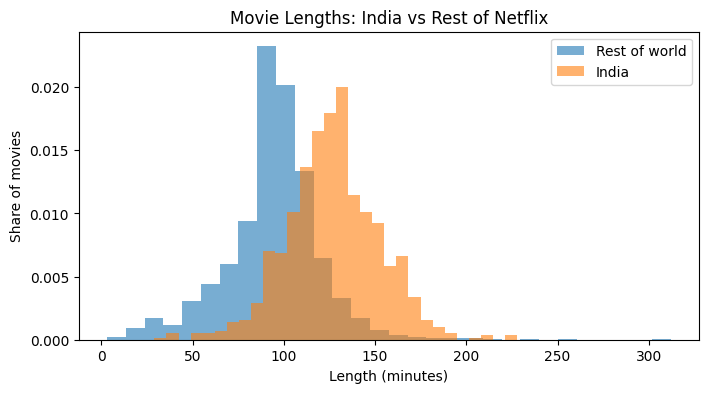

In [25]:
india = movies[movies['origin'] == 'India']['minutes']
rest = movies[movies['origin'] == 'Rest of world']['minutes']


plt.figure(figsize=(8, 4))
plt.hist(rest, bins=30, alpha=0.6, density=True, label='Rest of world')
plt.hist(india, bins=30, alpha=0.6, density=True, label='India')
plt.legend()
plt.title('Movie Lengths: India vs Rest of Netflix')
plt.xlabel('Length (minutes)')
plt.ylabel('Share of movies')
plt.show()

In [26]:
import seaborn as sns

sns.countplot(data=df, x='column', hue='column')
data= the table
x= / y= which column goes on which axis
hue= which column decides the colour (a free legend!)

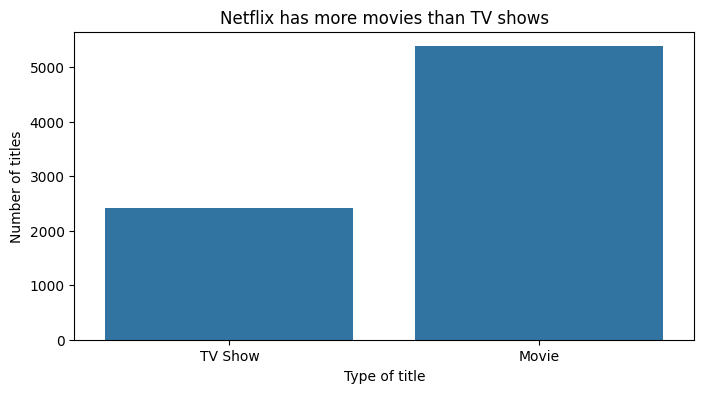

In [27]:
plt.figure(figsize=(8,4))
sns.countplot(data=df, x='type')
plt.title('Netflix has more movies than TV shows')
plt.xlabel('Type of title')
plt.ylabel('Number of titles')
plt.show()

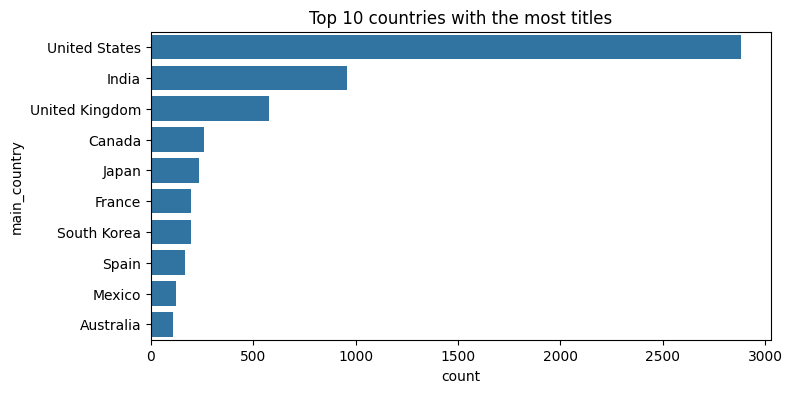

In [28]:
top_order = known['main_country'].value_counts().head(10).index

plt.figure(figsize=(8,4))
sns.countplot(data=known, y='main_country', order = top_order)
plt.title('Top 10 countries with the most titles')
plt.show()

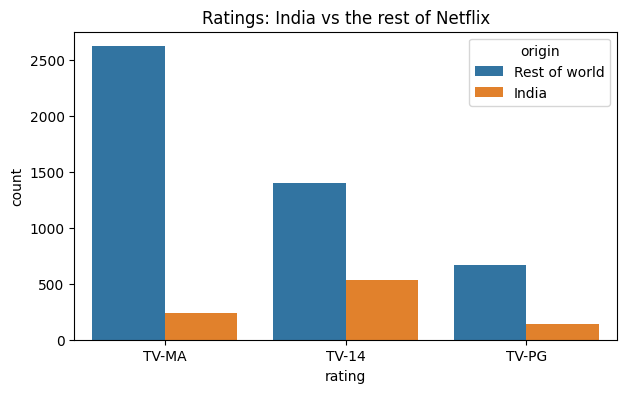

In [30]:
#  India: TV-14 is the most common (533 of its 956 titles); rest of world: TV-MA
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='rating', hue='origin', order=['TV-MA', 'TV-14', 'TV-PG'])
plt.title('Ratings: India vs the rest of Netflix')
plt.show()